<a href="https://colab.research.google.com/github/3b232106/2026_DL_hws/blob/main/hw5_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 作業5-1 - 四資四乙 3B232106 陳威廷

# a. 資料預處理

In [ ]:
import urllib.request
import os
import tarfile

## 解壓縮IMDb

In [ ]:
if not os.path.exists("data/aclImdb"):
    tfile = tarfile.open("data/aclImdb_v1.tar.gz", 'r:gz')
    result=tfile.extractall('data/')

/tmp/ipykernel_569/2618287489.py:3: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  result=tfile.extractall('data/')


## 檢視data/aclImdb內的資料夾結構(解壓縮後)：



* **test** (影評25000篇，測試用)
  * **neg**: 有12500篇負面影評文字檔
  * **pos**: 有12500篇正面影評文字檔
* **train** (影評25000篇，訓練用)
  * **neg**: 有12500篇負面影評文字檔
  * **pos**: 有12500篇正面影評文字檔

## 匯入文字資料預處理模組

In [ ]:
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.preprocessing.text import Tokenizer

## 定義 rm_tags(text)函數

* 用以去除text當中的HTML標籤(tag)

In [ ]:
import re
def rm_tags(text):
    re_tag = re.compile(r'<[^>]+>')
    return re_tag.sub('', text)

## 定義 read_files(filetype)函數

* filetype可以是train或test
* 是train，則由data/aclImdb的train資料夾**讀取訓練資料**
* 是test，則由test資料夾**讀取測試資料**

In [ ]:
import os
def read_files(filetype):
    path = "data/aclImdb/"
    file_list=[]

    positive_path=path + filetype+"/pos/"
    for f in os.listdir(positive_path):
        file_list+=[positive_path+f]

    negative_path=path + filetype+"/neg/"
    for f in os.listdir(negative_path):
        file_list+=[negative_path+f]

    print('read',filetype, 'files:',len(file_list))

    all_labels = ([1] * 12500 + [0] * 12500)

    all_texts  = []
    for fi in file_list:
        with open(fi,encoding='utf8') as file_input:
            all_texts += [rm_tags(" ".join(file_input.readlines()))]

    return all_labels,all_texts

## 建立訓練與測試資料

In [ ]:
y_train,train_text=read_files("train")
y_test,test_text=read_files("test")

read train files: 25000
read test files: 25000


In [ ]:
#查看正面評價的影評
train_text[0]

"So i consider myself pretty big into the anime scene, with very few shows i simply WILL NOT WATCH.this show, however, i would recommend to anyone.Quite possibly the most Original series to date, it;s got just about everything i could ask for. A side story, so to speak, about an unconditional love that will NOT be admitted to, a very blatant comedy, and a very well put together voice acting cast (both Japanese and American translation).If not for the terribly funny aspect to it, it would be, just another anime.More or less, as i have noticed, a 'love it or hate it', very few people i have seen introduced to this series will end up with a distaste for it.Original to the core, with everything you could ask for in an afternoon, bet the house on this series. I'm ready to ASSURE you that you will enjoy it."

In [ ]:
y_train[0]

1

In [ ]:
#查看負面評價的影評
train_text[12500]

'Let\'s see. In the "St. Elsewhere" finale we found out that there was no hospital and that every thing had been in the mind of an autistic child. "Newhart" ended by telling us that it had all been a dream. And "Roseanne" ended by telling us that it all had taken place in her mind. Very "creative". Annoying was more like it. Yes, it was just a TV show and wasn\'t at all reality. It\'s just that when you get caught up in a great movie or TV show you end up at least wanting to believe that it\'s all "real". At least as far as the reality it portrays on screen. This type of series finale had been done twice before and was old hat, frustrating and simply not fun to watch. Now "Newhart" being all a dream? At least done in a creative way that far exceeded the expectations of anyone who loved the show. The idea itself was not too engaging but it was so brilliantly done that its arguably the Best Series Finale Ever. Roseanne left me feeling cheated after being such a loyal fan.'

In [ ]:
y_train[12500]

0

## 利用tokenizer建立字典

* 字典的數量限制為2000：nb_words=2000
* 讀取訓練資料所有影評(train_text)，依每一個**英文單字(word)**在訓練資料(所有影評文章)出現頻率排序，取最高前2000個單字及其順序數字(index)，形成一個字典

In [ ]:
tokenizer = Tokenizer(num_words=2000)
tokenizer.fit_on_texts(train_text)

In [ ]:
print(tokenizer.document_count)

25000


## 轉換每篇影評(文字串)為一連串的數字(數字串)

* 每篇影評所有**單字(word)**轉換為一個一個的數字(index)

In [ ]:
x_train_seq = tokenizer.texts_to_sequences(train_text)
x_test_seq  = tokenizer.texts_to_sequences(test_text)

In [ ]:
print(train_text[0])

So i consider myself pretty big into the anime scene, with very few shows i simply WILL NOT WATCH.this show, however, i would recommend to anyone.Quite possibly the most Original series to date, it;s got just about everything i could ask for. A side story, so to speak, about an unconditional love that will NOT be admitted to, a very blatant comedy, and a very well put together voice acting cast (both Japanese and American translation).If not for the terribly funny aspect to it, it would be, just another anime.More or less, as i have noticed, a 'love it or hate it', very few people i have seen introduced to this series will end up with a distaste for it.Original to the core, with everything you could ask for in an afternoon, bet the house on this series. I'm ready to ASSURE you that you will enjoy it.


In [ ]:
print(x_train_seq[0])

[34, 9, 1126, 542, 180, 190, 79, 1, 132, 15, 51, 167, 283, 9, 327, 76, 20, 102, 10, 119, 186, 9, 58, 382, 5, 255, 175, 864, 1, 87, 200, 197, 5, 1299, 8, 586, 184, 39, 40, 282, 9, 96, 938, 14, 3, 495, 61, 34, 5, 1124, 40, 31, 115, 11, 76, 20, 25, 5, 3, 51, 208, 2, 3, 51, 69, 272, 291, 540, 112, 173, 195, 855, 2, 294, 44, 20, 14, 1, 1896, 158, 1247, 5, 8, 8, 58, 25, 39, 155, 49, 38, 324, 13, 9, 24, 1916, 3, 8, 38, 777, 51, 167, 80, 9, 24, 106, 1719, 5, 10, 197, 76, 126, 52, 15, 3, 14, 8, 200, 5, 1, 15, 282, 21, 96, 938, 14, 7, 31, 1, 309, 19, 10, 197, 142, 1617, 5, 21, 11, 21, 76, 353, 8]


In [ ]:
# sequences_to_texts() 可以轉換數字為文字
tokenizer.sequences_to_texts([[10, 6, 3, 16, 11, 210, 124, 253, 54, 9, 63, 8, 46, 22, 34]])

['this is a movie that gets better each time i see it there are so']

## 完成x_train與x_test的建立：使每篇影評的數字串長度相同

In [ ]:
x_train = sequence.pad_sequences(x_train_seq, maxlen=100)
x_test  = sequence.pad_sequences(x_test_seq,  maxlen=100)

In [ ]:
#如果文章轉成數字不足100,pad_sequences處理後，前面會加上0
print('before pad_sequences length=',len(x_train_seq[0]))
print(x_train_seq[0])

before pad_sequences length= 141
[34, 9, 1126, 542, 180, 190, 79, 1, 132, 15, 51, 167, 283, 9, 327, 76, 20, 102, 10, 119, 186, 9, 58, 382, 5, 255, 175, 864, 1, 87, 200, 197, 5, 1299, 8, 586, 184, 39, 40, 282, 9, 96, 938, 14, 3, 495, 61, 34, 5, 1124, 40, 31, 115, 11, 76, 20, 25, 5, 3, 51, 208, 2, 3, 51, 69, 272, 291, 540, 112, 173, 195, 855, 2, 294, 44, 20, 14, 1, 1896, 158, 1247, 5, 8, 8, 58, 25, 39, 155, 49, 38, 324, 13, 9, 24, 1916, 3, 8, 38, 777, 51, 167, 80, 9, 24, 106, 1719, 5, 10, 197, 76, 126, 52, 15, 3, 14, 8, 200, 5, 1, 15, 282, 21, 96, 938, 14, 7, 31, 1, 309, 19, 10, 197, 142, 1617, 5, 21, 11, 21, 76, 353, 8]


In [ ]:
print('after pad_sequences length=',len(x_train[0]))
print(x_train[0])

after pad_sequences length= 100
[  96  938   14    3  495   61   34    5 1124   40   31  115   11   76
   20   25    5    3   51  208    2    3   51   69  272  291  540  112
  173  195  855    2  294   44   20   14    1 1896  158 1247    5    8
    8   58   25   39  155   49   38  324   13    9   24 1916    3    8
   38  777   51  167   80    9   24  106 1719    5   10  197   76  126
   52   15    3   14    8  200    5    1   15  282   21   96  938   14
    7   31    1  309   19   10  197  142 1617    5   21   11   21   76
  353    8]


In [ ]:
# 如果文章轉成數字長度大於100，pad_sequences處理後，會truncate前面的數字
print('before pad_sequences length=',len(x_train_seq[1]))
print(x_train_seq[1])

before pad_sequences length= 351
[3, 54, 262, 923, 5, 198, 1, 1037, 416, 1613, 40, 1, 584, 4, 3, 149, 154, 1, 584, 4, 3, 48, 997, 12, 111, 1947, 1, 260, 1, 157, 76, 335, 94, 272, 291, 28, 1, 1319, 4, 1, 11, 64, 7, 71, 22, 619, 5, 1, 4, 587, 892, 2, 67, 46, 6, 1070, 13, 33, 6, 1, 2, 517, 14, 1, 148, 972, 5, 25, 649, 108, 46, 1, 143, 731, 6, 30, 37, 55, 1056, 33, 12, 15, 7, 1, 37, 655, 2, 49, 1618, 242, 816, 29, 1, 1705, 1, 409, 1, 4, 43, 20, 305, 5, 23, 1728, 83, 26, 1948, 1, 15, 3, 1672, 7, 23, 1604, 33, 1, 1388, 966, 10, 128, 6, 7, 15, 1, 1388, 562, 128, 83, 26, 206, 162, 31, 1333, 5, 874, 1, 2, 79, 1, 1705, 28, 1, 54, 1, 6, 95, 72, 19, 6, 7, 23, 2, 490, 5, 25, 1198, 40, 8, 201, 332, 148, 177, 228, 5, 78, 15, 3, 488, 56, 23, 1728, 490, 86, 42, 4, 23, 17, 1, 416, 6, 83, 262, 35, 3, 192, 343, 4, 345, 7, 1, 564, 1143, 6, 551, 83, 23, 2, 14, 1269, 95, 72, 19, 23, 7, 652, 1643, 274, 825, 1038, 10, 1198, 1140, 4, 1, 109, 4, 3, 564, 1902, 7, 1, 2, 23, 998, 115, 15, 155, 1480, 997, 71, 193, 8

In [ ]:
print('after pad_sequences length=',len(x_train[1]))
print(x_train[1])

after pad_sequences length= 100
[ 119   35   38    1   88    5  975  130  143 1181  283    3 1475    5
   10 1828   59    6  205    1    1  416  234   24   73  612   15    3
  271  763   46    6    3 1277 1263   13    1  918   23  189    6  204
   19   15    3 1226    4   11  148   74   42    4  503  162   31  317
    5    1  119   13    1  173    6    2    8 1676   48   28  183  350
   35  312  461  439  459    7   10  386 1845  210    5   23    1  448
    4    1 1792    1 1248  558   23 1862  241 1845    6   14  879   15
    1  251]


## 轉換x_train, x_test, y_train, y_test為numpy array

import numpy as np

x_train = np.array(x_train)
x_test = np.array(x_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)

In [ ]:
import numpy as np

x_train = np.array(x_train)
x_test = np.array(x_test)
y_train = np.array(y_train)
y_test = np.array(y_test)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)

(25000, 100)
(25000, 100)
(25000,)


# b. 神經網路模型訓練

## 讀入所需套件

In [ ]:
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding
from tensorflow.keras.layers import LSTM
from tensorflow.keras.datasets import imdb

## 神經網路模型建立

In [ ]:
model = Sequential()

model.add(Embedding(input_dim=3000, output_dim=64, input_length=100))
# Embedding層參數個數 = 輸入大小*輸出大小 = 3000*64 = 192000

model.add(LSTM(64))
# LSTM層參數個數 = 4*(((輸入大小+輸出大小)*輸出大小)+輸出大小) = 4*(((64+64)*64)+64) = 33024

model.add(Dense(1, activation='sigmoid'))
# Dense層參數個數 = (輸入*輸出)+輸出 = (64*1)+1 = 65

## 組裝神經網路

In [ ]:
model.compile(loss='binary_crossentropy',
             optimizer='adam',
             metrics=['accuracy'])

## 檢視模型

In [ ]:
model.build(input_shape=(None, 100))
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 100, 64)        │       192,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,089 (879.25 KB)

 Trainable params: 225,089 (879.25 KB)

 Non-trainable params: 0 (0.00 B)

## 訓練模型

In [ ]:
train_history = model.fit(x_train, y_train, batch_size=32, epochs=10, validation_split=0.2)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 37s 57ms/step - accuracy: 0.7979 - loss: 0.4313 - val_accuracy: 0.7584 - val_loss: 0.6076
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 47s 66ms/step - accuracy: 0.8665 - loss: 0.3180 - val_accuracy: 0.8148 - val_loss: 0.3943
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step - accuracy: 0.8829 - loss: 0.2835 - val_accuracy: 0.7930 - val_loss: 0.5259
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 39s 57ms/step - accuracy: 0.8974 - loss: 0.2483 - val_accuracy: 0.8252 - val_loss: 0.3912
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 43s 60ms/step - accuracy: 0.9079 - loss: 0.2268 - val_accuracy: 0.7750 - val_loss: 0.6195
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 34s 54ms/step - accuracy: 0.9181 - loss: 0.2027 - val_accuracy: 0.8028 - val_loss: 0.5457
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 36s 58ms/step - accuracy: 0.9258 - loss: 0.1847 - val_accuracy: 0.8154 - val_loss: 0.5405
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 37s 60ms/step - accuracy: 0.9393 - loss: 0.1573 - 

## 以折線圖顯示訓練過程的 loss & accuracy

In [ ]:
import matplotlib.pyplot as plt

# 畫出訓練過程每一個epoch訓練資料與驗證資料各自準確率(accuracy)的變化，或者損失誤差(loss)的變化
def show_train_history(train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

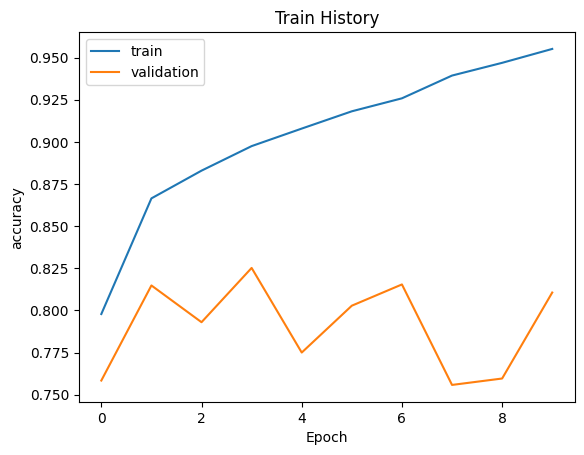

In [ ]:
# 準確率(accuracy)
show_train_history(train_history,'accuracy','val_accuracy')

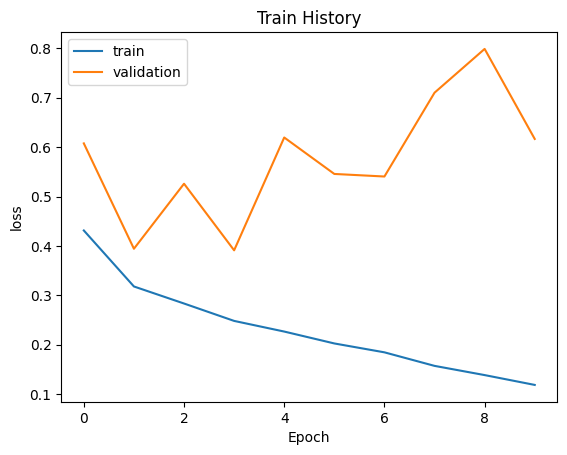

In [ ]:
# 損失誤差(loss)
show_train_history(train_history,'loss','val_loss')

## 評估模型準確率

In [ ]:
scores = model.evaluate(x_test, y_test)
print()
print('accuracy=',scores[1])

782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step - accuracy: 0.8378 - loss: 0.5274

accuracy= 0.8378000259399414


## 儲存模型與權重

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd '/content/drive/My Drive/Colab Notebooks'
model_json = model.to_json()
open('imdb_model_architecture.json', 'w').write(model_json)
model.save_weights('imdb_model.weights.h5')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/Colab Notebooks


## 儲存Tokenizer

In [ ]:
import pickle
f = open('SaveModel/3b232106_hw5_1.pkl', 'wb')
pickle.dump(tokenizer, f)
f.close()